## Домашнее задание № 1 (Макс. 10 баллов)

В данной домашней работе мы познакомимся на практике с пройденными темами, включающими в себя статистику, проверку гипотез и A/B тестирование.

### Задача 1 (2 балла)

**(1 Балл)** Рассчитайте среднее, стандартное отклонение и медиану по 1000 случайных выборок, порождённых нормальным распределением с $\mu = 5$ и $\sigma^2 = 4$, состоящих из 100 элементов. Постройте распределение полученных метрик.

100%|██████████| 1000/1000 [00:00<00:00, 16821.49it/s]


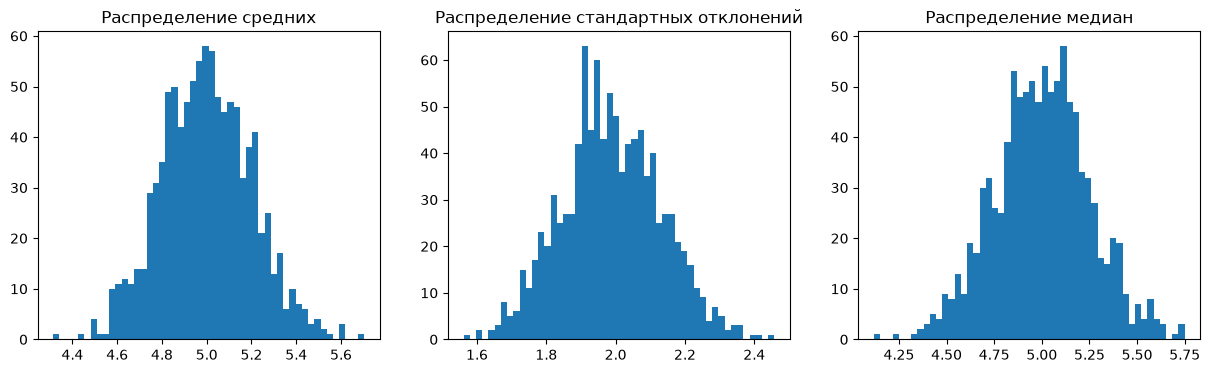

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as sps
from tqdm import tqdm

# сверху написано что sigma^2 = 4, буду считать в функции опечатка
# и sigma = 2

def calc_stat_random_sample(mu=5, sigma=2, size=100):
    data = np.random.normal(loc=mu, scale=sigma, size=size)

    mean = np.mean(data)
    std = np.std(data, ddof=1)
    median = np.median(data)

    return(mean, std, median)

n_samples = 1000

list_means = np.empty(n_samples)
list_stds = np.empty(n_samples)
list_medians = np.empty(n_samples)

for i in tqdm(range(n_samples)):
    mean, std, median = calc_stat_random_sample()
    list_means[i] = mean
    list_stds[i] = std
    list_medians[i] = median

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(list_means, bins=50)
ax[0].set_title('Распределение средних')

ax[1].hist(list_stds, bins=50)
ax[1].set_title('Распределение стандартных отклонений')

ax[2].hist(list_medians, bins=50)
ax[2].set_title('Распределение медиан')

plt.show()


**(1 Балл)** Какому распределению принадлежит распределение средних? Почему?

Нормальному по ЦПТ

Не знаю что еще тут дополнить, можно дополнить что параметры $\mathcal{N}(\mu, \frac{\sigma^2}{n})$ мат. ожидание и стандартная ошибка на гистограмме получилось примерно такое

### Задача 2 (2 балла):

Оцените значение $\hat{\mu}$ параметра $\mu$ **(1 балл)** для нормального распределения $\mathscr{N}(\mu,1)$ используя метод максимального правдоподобия.

Справка: функция плотности распределения для нормального распределения имеет вид:
$$
    f(x) = \frac{1}{\sqrt{2 \pi \sigma^2}} \text{e}^{-\frac{(x - \mu)^2}{2 \sigma^2}}
$$

Функция правдоподобия:

Считая что наблюдения независимы

$$L(\mu) = \prod_{i=1}^{n} f(x_i) = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \text{e}^{-\frac{(x - \mu)^2}{2 \sigma^2}}$$

При $\sigma^2 = 1$:

$$L(\mu) = \left(\frac{1}{\sqrt{2\pi}}\right)^n \text{e}^ {-\frac{1}{2} \sum_{i=1}^{n} (x_i - \mu)^2}$$

Её логарифм: 

$$\ln L(\mu) = \ln {(\frac{1}{\sqrt{2\pi}})^n} + \ln {(\text{e}^ {-\frac{1}{2} \sum_{i=1}^{n} (x_i - \mu)^2})}$$

$$\ln L(\mu) = -\frac{n}{2}\ln(2\pi) - \frac{1}{2} \sum_{i=1}^{n} (x_i - \mu)^2$$

Дифференцируем: 

$$\frac{\partial \ln L(\mu)}{\partial \mu} = -\frac{1}{2} \sum_{i=1}^{n} 2(x_i - \mu) \cdot (-1) = \sum_{i=1}^{n} (x_i - \mu)$$

Ищем экстремум, приравнивая производную к нулю

$$\sum_{i=1}^{n} (x_i - \hat{\mu}) = 0$$

Откуда получаем оценку $\hat{\mu}$:

$$\hat{\mu} = \frac{1}{n} \sum_{i=1}^{n} x_i $$


Сгенерируйте 1000 выборок размером 1000 наблюдений из нормального распределения с $\mu = 5, \sigma^2 = 1$, постройте распределение разности $\mu - \hat{\mu}$ и найдите среднее этой разности в зависимости от числа выборок **(1 балл)**.

Ну для каждого количества выборок получится свое среднее и найден будет целый массив, либо я не понял задание. 
Я постороил гистограмму этих средних.

100%|██████████| 1000/1000 [00:00<00:00, 29670.45it/s]


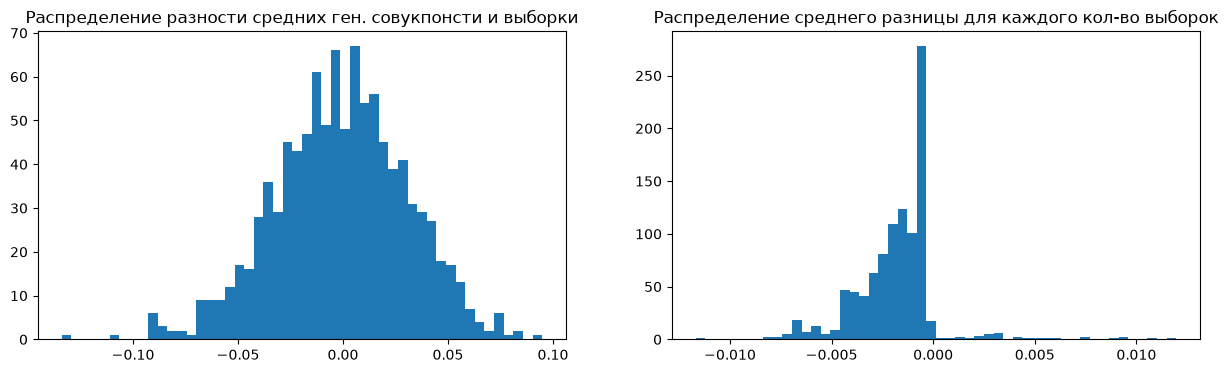

In [12]:
def calculate_stat_random_sample(mu=5, sigma=1, size=1000):
    data = np.random.normal(loc=mu, scale=sigma, size=size)

    diff_means = mu - np.mean(data)

    return diff_means

n_samples = 1000

list_diff_means = np.empty(n_samples)
list_diff_means_for_n = np.empty(n_samples)
total_sum = 0

for i in tqdm(range(1, n_samples + 1)):
    mean = calculate_stat_random_sample()
    total_sum += mean

    list_diff_means[i - 1] = mean
    list_diff_means_for_n[i - 1] = total_sum / i


fig, ax = plt.subplots(1, 2, figsize=(15, 4))

ax[0].hist(list_diff_means, bins=50)
ax[0].set_title('Распределение разности средних ген. совукпонсти и выборки')

ax[1].hist(list_diff_means_for_n, bins=50)
ax[1].set_title('Распределение среднего разницы для каждого кол-во выборок')

plt.show()


### Задача 3 (2 балла)

**(1 балл)** Пусть известно, что выборка в n наблюдений порождена распределением Бернулли ~Bernoulli(p), пусть среднее значение по выборке равно $\hat{p}$. Постройте формулу 95% доверительного интервал для среднего

Для выборки c распределением Бернулли:
- Cреднее: $\hat{p}$
- Тогда дисперсия : $\hat{p}(1 - \hat{p})$ 

По ЦПТ при больших $n$ распределение средних сходиться к нормальному распределению с параметрами $\mathcal{N}(\hat{p}, \sqrt{\frac{\hat{p}(1-\hat{p})}{n}})$

Так как n большое то $\mathcal{N}(\hat{p}, 1)$

Мы хотим записать границы 95% доверительного интервала, тоесть с каждой стороны нашего симместричного распределения убрать 2.5%, если мы конечно хотим постороить двухстороний доверительный интеревал, так как не сказано иного то запишу границы именно для такого.

Нам нужно значение 1 - $\alpha$ / 2 = 0.975 квантиля для стандартного нормального распределения, для нашего распределения ничего не изменится ведь стандартное отклонение у него такое же, просто график будет смещен на мат ожидание.

Значение это можно найти как: $value = sps.norm.ppf(0.975) \approx 1.96$

Границы 95% двухстроннего доверительного интервала:
$$ (\hat{p} - 1.96 \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}, \quad \hat{p} + 1.96 \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}})$$

**(1 балл)** Постройте 95% доверительный интервал на среднее в представленной выборке, используя бутстрап и сравните с теоретическим значением

In [4]:
p = 0.2
n = 10000
X = sps.bernoulli.rvs(p, size = n, random_state=42)

quan_95 = sps.norm.ppf(0.975)
std = np.sqrt(p * (1 - p) / n)

left_value = p - quan_95 * std
right_value = p + quan_95 * std

boot_means = np.empty(n)

np.random.seed(42)

for i in range(n):
    boot_sample = np.random.choice(X, size=n, replace=True)
    boot_means[i] = np.mean(boot_sample)

left_boot_value = np.percentile(boot_means, 2.5)
right_boot_value = np.percentile(boot_means, 97.5)

print(f"p = {p}")
print(f"Теоретический расчет границ: {left_value:.3f}, {right_value:.3f}")
print(f"Bootstrap расчет границ: {left_boot_value:.3f}, {right_boot_value:.3f}")


p = 0.2
Теоретический расчет границ: 0.192, 0.208
Bootstrap расчет границ: 0.188, 0.204


У bootstrap значения границ отличаются немного, что и не удивительно.

### Задача 4 (4 балла)

Основным критерием для тестирования гипотезы о равенстве средних является t-test. Он строится на том, что по ЦПТ практически для любой случайной величины средние будут распределены нормально. 

В учебниках по статистике доказывается, что в силу этого для двух выборок, порождённых одинаково распределёнными независимыми случайными величинами с равным средним мы имеем асимпототику для выборочной t-статистики
$$
    T = \frac{\bar{x} - \bar{y}}{\sqrt{\frac{s_x^2}{n_1} + \frac{s_y^2}{n_2}}} \rightarrow t_{n_1 + n_2 - 2},
$$
где $\bar{x}, \bar{y}$ -- выборочные средние в выборках, $s_x^2, s_y^2$ -- выборочные дисперсии, $n_1, n_2$ -- размеры выборок, а $t_{n_1 + n_2 - 2}$ -- распределение Стьюдента с $n_1 + n_2 - 2$ степенями свободы.

**(1 балл)** Постройте плотность распределения Стьюдента с 1, 5, 10, 100 и 1000 степеней свободы, а также плотность стандартного нормального распределения

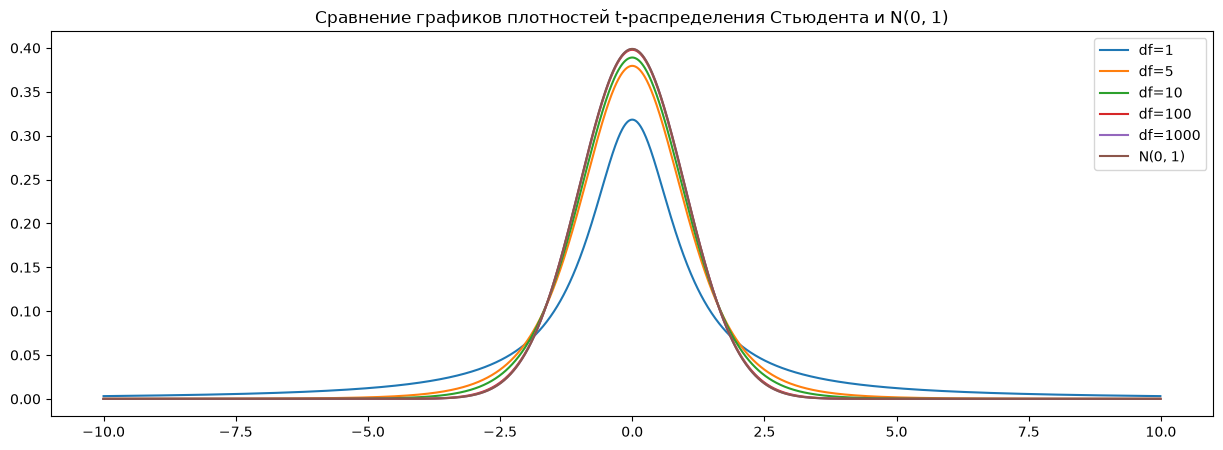

In [5]:
grid = np.arange(-10,10,0.01)

freedom_degrees = [1,5,10,100,1000]

plt.figure(figsize=(15, 5))

for deg in freedom_degrees:
    pdf_deg = sps.t.pdf(grid, df=deg)
    plt.plot(grid, pdf_deg, label=f"df={deg}")

pdf_norm = sps.norm.pdf(grid)
plt.plot(grid, pdf_norm, label='N(0, 1)')

plt.title('Сравнение графиков плотностей t-распределения Стьюдента и N(0, 1)')
plt.legend()
plt.show()


**(1 балл)** Пусть нам необходимо запустить A/B тест: в первой группе мы оставляем кнопку в банковском приложении в сером цвете, во втором -- красим её в жёлтый. Всего у нас в месяц в приложение заходит 1000 различных клиентов. Базовая конверсия в нажатие кнопки сейчас составляет 0.2. Бизнес постановил, что MDE = 5%, то есть значимым будет считаться изменение, при котором конверсия будет больше 0.21 или меньше 0.19. Хватит ли нам данных, чтобы замерить эффект за один месяц при уровне значимости $\alpha = 0.05$, если мы планируем поделить выборку пополам на тест и контроль?

In [6]:
mu1, mu2 = 0.2, 0.21
alpha = 0.05
beta = 0.2

t_alpha = sps.norm.ppf(1 - alpha/2)
t_beta = sps.norm.ppf(1 - beta)

var_A = mu1 * (1 - mu1)
var_B = mu2 * (1 - mu2)

mde = mu2 - mu1

n = ((var_A + var_B) * (t_alpha + t_beta) ** 2) / (mde ** 2)

print(f"Для замера эффекта нужно {int(np.ceil(n))} человек на тестовую и контрольную выборку")


Для замера эффекта нужно 25580 человек на тестовую и контрольную выборку


**(1 балл)** Мы провели тест и получили следующие результаты:

In [7]:
X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000, random_state=42), sps.bernoulli.rvs(0.21, size = 1000, random_state=42)

Можем ли мы утверждать на уровне значимости $\alpha = 0.05$, что эффект имел место быть?

In [8]:
t_stat, p_val = sps.ttest_ind(X_1, X_2, equal_var=False)
print(f"Значение p-value: {p_val}")

Значение p-value: 0.5065043374621505


Так как p-value > 0.05, то мы не можем утверждать что эффект имел место быть.

**(1 балл)** 

Что будет, если мы проведём 1000 таких тестов, "отпустив" random_state?

В какой доле случаев мы не задетектируем это существующее различие? Чему будет равна $\beta$?

In [9]:
# Под "отпущенным" random_state понимается None
n = 1000

p_value_arr = np.zeros(n)

for i in range(n):
    X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000), sps.bernoulli.rvs(0.21, size = 1000)
    t_stat, p_val = sps.ttest_ind(X_1, X_2, equal_var=False)
    p_value_arr[i] = p_val

hat_beta = np.mean(p_value_arr > 0.05)

print(f"Доля случаев, когда различие не задетектировано: {hat_beta:.3f}")


Доля случаев, когда различие не задетектировано: 0.910


Не понятно нужно ли мне оценить и просто сказать, что это мы находим оценку beta. Или найти теоретическое значение beta. Ниже я выразил ее из формулы и посчитал, результаты оказались похожими.

In [10]:
n = 1000
mu1, mu2 = 0.2, 0.21
alpha = 0.05
mde = mu2 - mu1

t_alpha = sps.norm.ppf(1 - alpha/2)

var_A = mu1 * (1 - mu1)
var_B = mu2 * (1 - mu2)

t_beta = np.sqrt((n * mde ** 2) / (var_A + var_B)) - t_alpha

print(1 - sps.norm.cdf(t_beta))

0.9201424278035583


А если различий не будет (при проведении 1000 A/A-тестов)? Как будет распределено p-value в этом случае?

Доля случаев, когда различие не задетектировано: 0.960


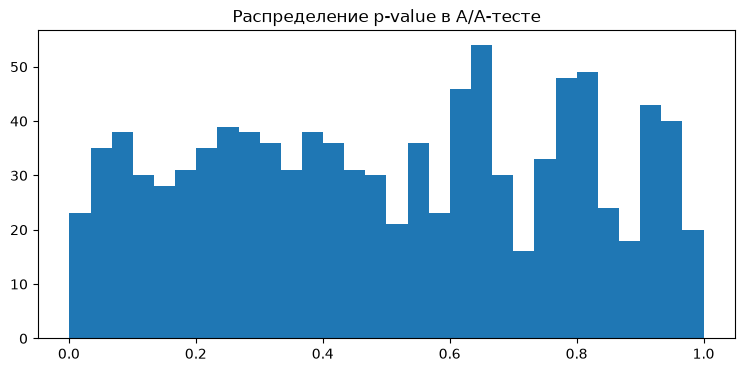

In [ ]:
# Под A/A тестом имеем в виду: X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000), sps.bernoulli.rvs(0.2, size = 1000)

n = 1000
p_value_arr = np.zeros(n)

for i in range(n):
    X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000), sps.bernoulli.rvs(0.2, size = 1000)
    t_stat, p_val = sps.ttest_ind(X_1, X_2, equal_var=False)
    p_value_arr[i] = p_val

hat_beta = np.mean(p_value_arr > 0.05)

print(f"Доля случаев, когда различие не задетектировано: {hat_beta:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(p_value_arr, bins=30)
ax.set_title('Распределение p-value в A/A-тесте')

plt.show()

В этом случае распределение будет равномерным, что можно увидеть на гистограмме.